**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**04 | Subject-Independent Data Splitting**

![Stage 04 scientific workflow](../../images/04_workflow.svg)

**Objective:** Construct activity windows and statistical features from eight HARTH participants, then create reproducible, participant-disjoint Train, Validation and exploratory Test partitions.

**Dataset:** Eight selected recordings from the pinned HARTH v2.0 release, each containing lower-back and thigh acceleration at 50 Hz.

**Notebook Scope:** Build participant-specific windows and features, split whole participants into 4/2/2 groups, and inspect class coverage. This is an early exploratory split, not the later frozen HARTH Development/Test protocol. No model is fitted.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ----------------------------- Standard Library ------------------------------
import sys
from pathlib import Path

# ---------------------- Data Analysis and Visualisation ----------------------
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------- Repository Configuration --------------------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root.parent == root: raise RuntimeError("Not inside the project")
    root = root.parent

sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- Shared Windowing and Splitting Utilities ------------------
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features
from core.data_splitting import split_group_indices

# -------------------------- HARTH Dataset Utilities --------------------------
from harth_data import ACTIVITY_NAMES, ensure_harth_sample, load_harth_subject

# --------------------- Plot Style and Environment Check ----------------------
from core.plot_style import plot_style
plot_style()

print("Shared Python functions: ready")


Shared Python functions: ready


**02. Acquire an Eight-Participant HARTH Subset**

Retrieve the selected public recordings or reuse their local cached copies. The source files are kept under the Git-ignored `data/raw/` directory.

In [3]:
# =================== 02. Acquire Eight HARTH Participants ====================

# --------------------------- Participant Selection ---------------------------
SUBJECTS = ["S023", "S024", "S025", "S027", "S028", "S032", "S034", "S035"]

# ------------------- Source Cache and Recording Retrieval --------------------
SOURCE = root / "data/raw/harth_v2"

paths = {s: ensure_harth_sample(SOURCE, subject=s) for s in SUBJECTS}

# ----------------------------- Source File Audit -----------------------------
display(pd.DataFrame([
    {"subject": s, "MiB": round(paths[s].stat().st_size/1048576,2)}
    for s in SUBJECTS
]))


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S023.csv


Downloaded 16,722,098 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S024.csv
Downloaded 21,695,989 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S025.csv
Downloaded 15,873,565 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S027.csv
Downloaded 16,949,909 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S028.csv
Downloaded 14,821,095 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S032.csv
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv


,subject,MiB
0,S023,11.50
1,S024,15.95
2,S025,20.69
3,S027,15.14
4,S028,16.16
5,S032,14.13
6,S034,14.34
7,S035,14.21


**03. Construct Windows and Features for Each Participant**

Apply the two-second windowing protocol and five feature methods from Notebooks 02 and 03 separately to each participant before combining rows. Codes `10` and `11` occur in the `S032.csv` source but have no published HARTH v2.0 activity descriptions; retain and flag them without assigning activity names.

In [4]:
# ================== 03. Construct Person-Specific Features ===================

# ----------------------- Participant-Level Containers ------------------------
feature_blocks, metadata_blocks, subjects_summary = [], [], []

# ------------ Source Validation, Windowing and Feature Extraction ------------
for subject in SUBJECTS:
    data, channels = load_harth_subject(
        paths[subject], allow_unmapped_labels=True  # Keep source-unknown activity codes for the audit.
    )
    unknown_mask = ~data["label"].isin(ACTIVITY_NAMES)
    unknown_codes = sorted(data.loc[unknown_mask, "label"].unique().tolist())
    if unknown_codes:
        print(f"{subject}: undocumented HARTH codes = {unknown_codes}")
    X, y, info = create_signal_windows(
        data[channels].to_numpy(), data["label"].to_numpy(),
        window_size=100, step_size=50,
        timestamps=data["timestamp"], sampling_rate=50,
        min_label_purity=1.0, subject_id=subject,  # Reject windows spanning different activity labels.
    )
    if not len(X): raise ValueError(f"No valid windows for {subject}")
    features = extract_signal_features(X, channel_names=channels)
    feature_blocks.append(features)
    metadata_blocks.append(info)
    subjects_summary.append({"subject":subject,"raw_samples":len(data),
                             "valid_windows":len(y),"classes":len(np.unique(y)),
                             "unmapped_rows":int(unknown_mask.sum()),
                             "unmapped_codes":str(unknown_codes)})

# --------------------- Combined Features and Provenance ----------------------
feature_table = pd.concat(feature_blocks, ignore_index=True)
window_metadata = pd.concat(metadata_blocks, ignore_index=True)

# ----------------- Feature Alignment and Participant Summary -----------------
assert len(feature_table) == len(window_metadata)

display(pd.DataFrame(subjects_summary))
print("Combined feature matrix:",feature_table.shape)


HARTH subject S023: 137,646 rows, 6 sensors
Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Input windows: (2567, 6, 100)
Feature matrix: (2567, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,272 | Shape: (4272, 6, 100)
Rejected candidates: 361
Input windows: (4272, 6, 100)
Feature matrix: (4272, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
HARTH subject S027: 158,584 rows, 6 sensors
Input signal: 158,584 samples, 6 channels
Candidate windows: 3

/tmp/ipykernel_18636/3878228903.py:8: UserWarning: Unexpected HARTH activity codes: [10, 11] (2,018 rows in S032.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S032: 178,341 rows, 6 sensors
S032: undocumented HARTH codes = [10, 11]
Input signal: 178,341 samples, 6 channels
Candidate windows: 3,565
Retained windows: 3,038 | Shape: (3038, 6, 100)
Rejected candidates: 527
Input windows: (3038, 6, 100)
Feature matrix: (3038, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Input windows: (3337, 6, 100)
Feature matrix: (3337, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length


,subject,raw_samples,valid_windows,classes,unmapped_rows,unmapped_codes
0,S023,137646,2567,8,0,[]
1,S024,170534,3119,8,0,[]
2,S025,231729,4272,12,0,[]
3,S027,158584,3082,6,0,[]
4,S028,165178,3197,7,0,[]
5,S032,178341,3038,7,2018,"[10, 11]"
6,S034,188202,3351,7,0,[]
7,S035,181251,3337,5,0,[]


Combined feature matrix: (25963, 30)


**04. Split Participants, Not Overlapping Windows**

Assign four participants to Train, two to Validation and two to an exploratory Test partition using the fixed random seed. The split operates on participant IDs rather than individual windows. These exploratory groups are distinct from the subsequently approved Development/Test protocol.

In [5]:
# ================ 04. Create Participant-Disjoint Partitions =================

# -------------------- Participant-Level Data Partitioning --------------------
partitions = split_group_indices(
    window_metadata["subject_id"].to_numpy(),
    train_fraction=0.50, validation_fraction=0.25,
    test_fraction=0.25, random_state=42,
)

# ------------------- Group Separation and Window Coverage --------------------
groups = {
    name: set(window_metadata.iloc[index]["subject_id"])
    for name,index in partitions.items()
}

assert not (groups["train"]&groups["validation"] or
            groups["train"]&groups["test"] or groups["validation"]&groups["test"])

np.testing.assert_array_equal(
    np.sort(np.concatenate(list(partitions.values()))),
    np.arange(len(window_metadata))
)

# ----------------------------- Partition Summary -----------------------------
display(pd.DataFrame([
    {"partition":p,"subjects":len(groups[p]),"windows":len(ix),
     "IDs":", ".join(sorted(groups[p]))}
    for p,ix in partitions.items()
]))
print("Subject leakage: NONE")


Independent groups: 8
train: 4 groups | 13,888 rows
validation: 2 groups | 6,470 rows
test: 2 groups | 5,605 rows


,partition,subjects,windows,IDs
0,train,4,13888,"S025, S027, S028, S035"
1,validation,2,6470,"S024, S034"
2,test,2,5605,"S023, S032"


Subject leakage: NONE


**05. Compare Activity Distributions Across Partitions**

Compare within-partition activity percentages using a grouped bar chart and a corresponding activity-by-partition heatmap. Different window counts make raw totals less suitable for comparing proportions. Retain explicit identifiers for undocumented label codes; this audit does not authorise supervised modelling with them.

,train,validation,test
1: Walking,6053,2009,3013
2: Running,3283,511,441
3: Shuffling,91,58,25
4: Stairs ascending,76,82,52
5: Stairs descending,54,65,26
6: Standing,700,1219,759
7: Sitting,1039,1547,650
8: Lying,1193,979,638
10: UNDOCUMENTED source code,0,0,1
13: Cycling seated,1018,0,0


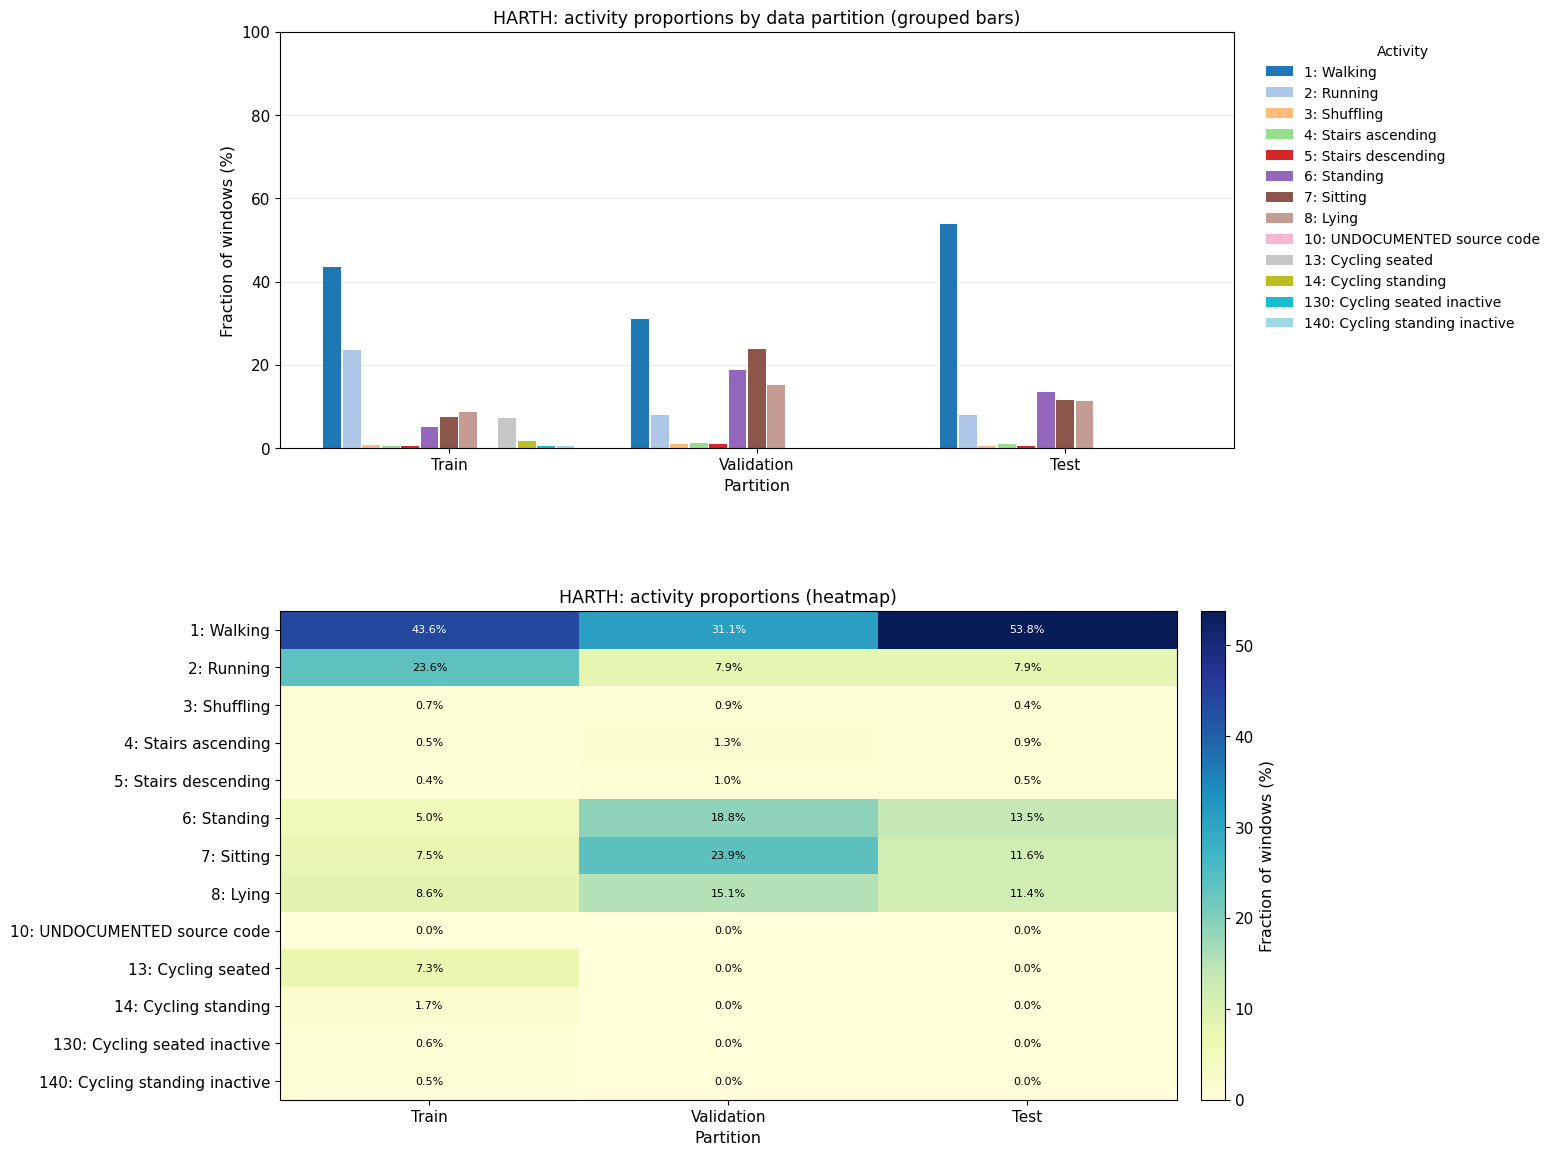

Classes absent by partition: {'train': ['10: UNDOCUMENTED source code'], 'validation': ['10: UNDOCUMENTED source code', '13: Cycling seated', '14: Cycling standing', '130: Cycling seated inactive', '140: Cycling standing inactive'], 'test': ['13: Cycling seated', '14: Cycling standing', '130: Cycling seated inactive', '140: Cycling standing inactive']}
Undocumented codes in retained windows: [np.int64(10)]
Classification with undocumented codes: NOT APPROVED


In [6]:
# =============== 05. Compare Partition Activity Distributions ================

# ----------------------- Activity Counts by Partition ------------------------
partition_order = ["train", "validation", "test"]
counts = pd.DataFrame({
    part: window_metadata.iloc[partitions[part]]["label"].value_counts()
    for part in partition_order
}).fillna(0).astype(int).sort_index()
counts.index = [
    f"{int(code)}: {ACTIVITY_NAMES.get(int(code), 'UNDOCUMENTED source code')}"
    for code in counts.index
]
display(counts)

# ------------------- Within-Partition Activity Percentages -------------------
fractions = counts.div(counts.sum(axis=0), axis=1) * 100
activity_names = fractions.index.tolist()
n_activities = len(activity_names)
positions = np.arange(len(partition_order))
bar_width = 0.82 / n_activities
colours = plt.get_cmap("tab20")(np.linspace(0, 1, n_activities))

fig, (ax_bars, ax_heatmap) = plt.subplots(
    2, 1, figsize=(18, 12),
    gridspec_kw={"height_ratios": [1.15, 1.35]},
)

# -------------------------- Grouped Bar Comparison ---------------------------
for i, (activity, colour) in enumerate(zip(activity_names, colours)):
    x_positions = positions + (i - (n_activities - 1) / 2) * bar_width
    ax_bars.bar(
        x_positions,
        fractions.loc[activity, partition_order].to_numpy(),
        width=bar_width * 0.92,
        label=activity,
        color=colour,
    )

ax_bars.set_xticks(positions, ["Train", "Validation", "Test"])
ax_bars.set(
    title="HARTH: activity proportions by data partition (grouped bars)",
    xlabel="Partition",
    ylabel="Fraction of windows (%)",
    ylim=(0, 100),
)
ax_bars.grid(axis="y", alpha=0.25)
ax_bars.set_axisbelow(True)
ax_bars.legend(
    title="Activity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

# ------------------------ Activity Proportion Heatmap ------------------------
heat_values = fractions[partition_order].to_numpy()
heatmap = ax_heatmap.imshow(
    heat_values,
    aspect="auto",
    cmap="YlGnBu",
    vmin=0,
    vmax=max(1.0, float(heat_values.max())),
)
ax_heatmap.set_xticks(positions, ["Train", "Validation", "Test"])
ax_heatmap.set_yticks(np.arange(n_activities), activity_names)
ax_heatmap.set(title="HARTH: activity proportions (heatmap)", xlabel="Partition")

# ------------------------- Heatmap Percentage Labels -------------------------
for row in range(n_activities):
    for column in range(len(partition_order)):
        value = heat_values[row, column]
        text_colour = "white" if value > heat_values.max() * 0.55 else "black"  # Improve contrast for larger values.
        ax_heatmap.text(
            column, row, f"{value:.1f}%",
            ha="center", va="center", fontsize=8, color=text_colour,
        )

# ---------------------- Figure Layout and Colour Scale -----------------------
colourbar = fig.colorbar(heatmap, ax=ax_heatmap, fraction=0.035, pad=0.025)
colourbar.set_label("Fraction of windows (%)")
fig.subplots_adjust(left=0.25, right=0.78, top=0.95, bottom=0.06, hspace=0.36)
plt.show()

# ------------------ Missing and Undocumented Activity Codes ------------------
print("Classes absent by partition:", {
    part: counts.index[counts[part] == 0].tolist()
    for part in partition_order
})

unmapped_window_codes = sorted(
    set(window_metadata["label"].unique()) - set(ACTIVITY_NAMES)
)
print("Undocumented codes in retained windows:", unmapped_window_codes)
print("Classification with undocumented codes: NOT APPROVED")


**06. Participant-Independent Quality Gate**

Verify feature dimensions, finite values, complete partition coverage and non-overlapping participant IDs. The checks establish separation of this exploratory cohort, not classifier performance or external validity. Undocumented activity codes require review before supervised training.


In [ ]:
# =================== 06. Subject-Independent Quality Gate ====================

# ---------------- Feature Integrity and Participant Coverage -----------------
assert feature_table.shape[1] == 30
assert np.isfinite(feature_table.to_numpy()).all()
assert window_metadata["subject_id"].nunique() == 8
assert len(feature_table) == sum(len(ix) for ix in partitions.values())

# ----------------- Partition-Level Feature and Label Shapes ------------------
for part,ix in partitions.items():
    print(f"{part}: X={feature_table.iloc[ix].shape}, y={window_metadata.iloc[ix]['label'].shape}")

# ----------------------- Quality Gate and Label Review -----------------------
print("Subject-independent splitting: PASSED")
print("Feature scaling trained: NO | Classifier trained: NO")
print("Undocumented label review required:", bool(unmapped_window_codes))


train: X=(13888, 30), y=(13888,)
validation: X=(6470, 30), y=(6470,)
test: X=(5605, 30), y=(5605,)
Subject-independent splitting: PASSED
Feature scaling trained: NO | Classifier trained: NO
Undocumented label review required: True
